# Employee Attrition Prediction using Machine Learning

### Summer Internship 2026
**Institution:** IIHMF, MNNIT Prayagraj

**Project By:** Aditya Verma

---

## Objective

The objective of this project is to predict whether an employee is likely to leave an organization based on various employee-related attributes using Machine Learning techniques.

## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


## Loading the Dataset

In [2]:
df = pd.read_csv("../data/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv")

## Viewing the Dataset

In [3]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## Dataset Dimensions

In [5]:
df.shape

(1470, 35)

## Dataset Features

In [6]:
df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')

## Dataset Information

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

## Statistical Summary

In [9]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


## Understanding the Target Variable

In [10]:
df["Attrition"].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

## Distribution of the Target Variable

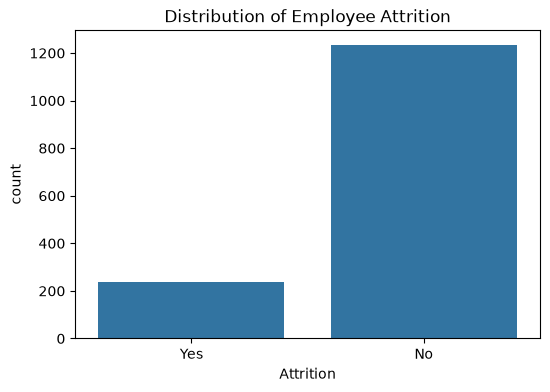

In [11]:
plt.figure(figsize=(6,4))

sns.countplot(x="Attrition", data=df)

plt.title("Distribution of Employee Attrition")

plt.show()

## Exploratory Data Analysis (EDA)

### Age Distribution

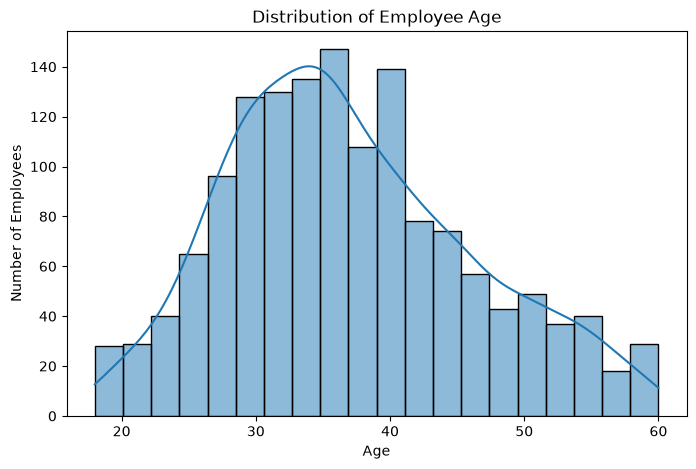

In [12]:
plt.figure(figsize=(8,5))

sns.histplot(df["Age"], bins=20, kde=True)

plt.title("Distribution of Employee Age")

plt.xlabel("Age")

plt.ylabel("Number of Employees")

plt.show()

### Age vs Attrition

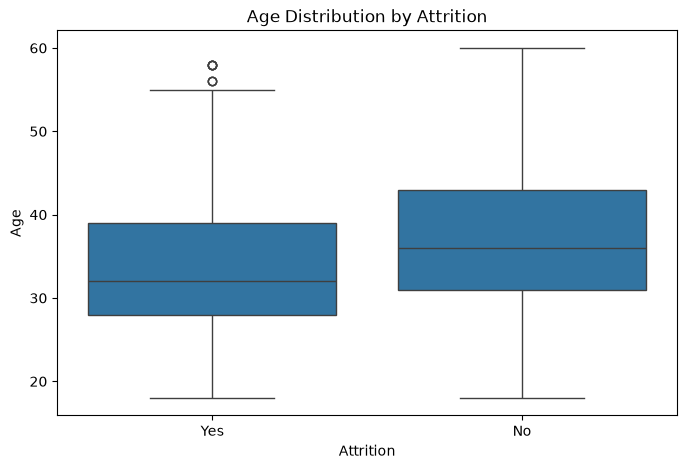

In [13]:
plt.figure(figsize=(8,5))

sns.boxplot(x="Attrition", y="Age", data=df)

plt.title("Age Distribution by Attrition")

plt.xlabel("Attrition")

plt.ylabel("Age")

plt.show()

### Observation

The median age of employees who left the company is slightly lower than that of employees who stayed. This indicates that younger employees appear to have a slightly higher tendency to leave the organization. However, the age distributions overlap considerably, suggesting that age alone is not sufficient to predict employee attrition.

### Gender vs Attrition

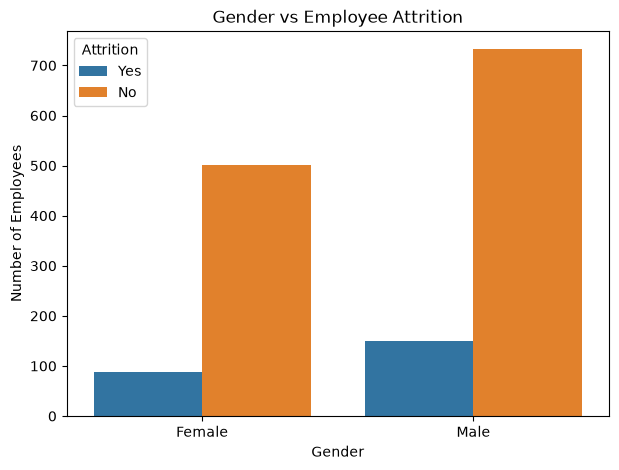

In [15]:
plt.figure(figsize=(7,5))

sns.countplot(x="Gender", hue="Attrition", data=df)

plt.title("Gender vs Employee Attrition")

plt.xlabel("Gender")

plt.ylabel("Number of Employees")

plt.show()

### Observation

The organization has more male employees than female employees. Although the number of male employees who left the company is higher, this is largely because the male population is larger. Based on this graph alone, gender does not appear to be a strong factor influencing employee attrition.

### Overtime vs Attrition

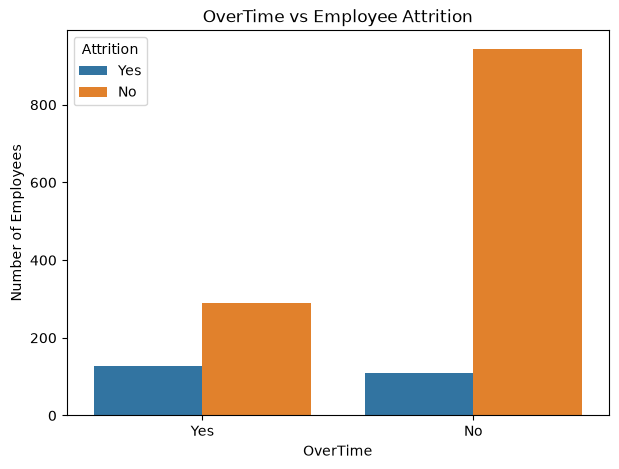

In [17]:
plt.figure(figsize=(7,5))

sns.countplot(x="OverTime", hue="Attrition", data=df)

plt.title("OverTime vs Employee Attrition")

plt.xlabel("OverTime")

plt.ylabel("Number of Employees")

plt.show()

### Observation

Employees who work overtime show a noticeably higher level of attrition compared to employees who do not work overtime. This suggests that overtime is an important factor associated with employee turnover and is likely to be a valuable feature for predicting attrition.

### Job Satisfaction vs Attrition

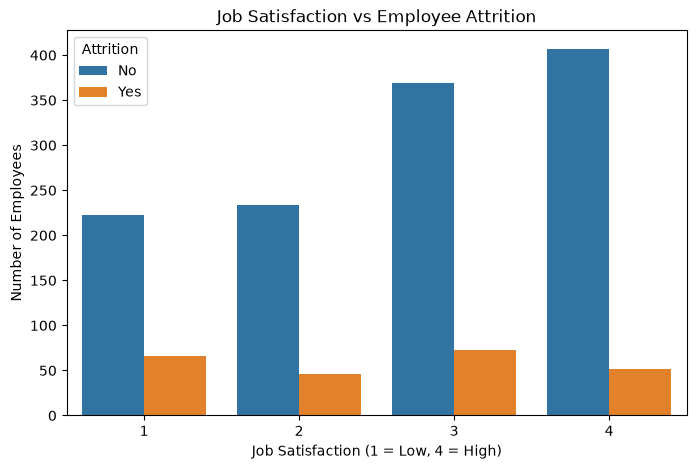

In [18]:
plt.figure(figsize=(8,5))

sns.countplot(x="JobSatisfaction", hue="Attrition", data=df)

plt.title("Job Satisfaction vs Employee Attrition")

plt.xlabel("Job Satisfaction (1 = Low, 4 = High)")

plt.ylabel("Number of Employees")

plt.show()

### Department vs Attrition

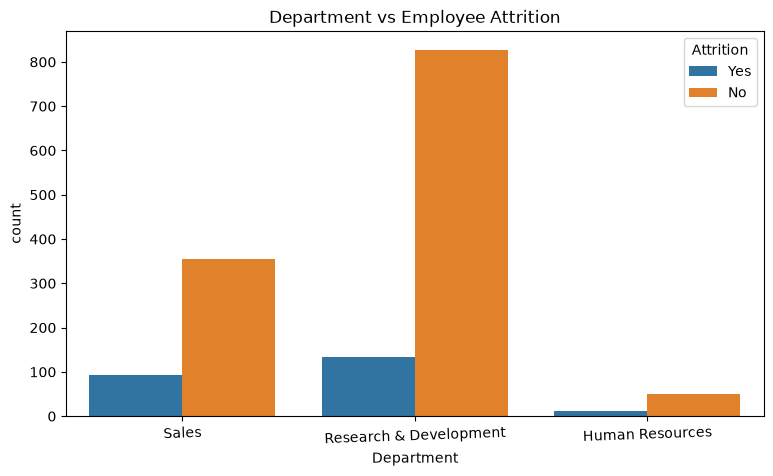

In [22]:
plt.figure(figsize=(9,5))

sns.countplot(x="Department", hue="Attrition", data=df)

plt.title("Department vs Employee Attrition")

plt.xticks(rotation=2)

plt.show()

Employees from Research & Development have the highest number of attrition cases, followed by Sales. However, this is expected because these departments also have more employees. HR has the lowest number of employees and consequently fewer attrition cases.

### Monthly Income vs Attrition

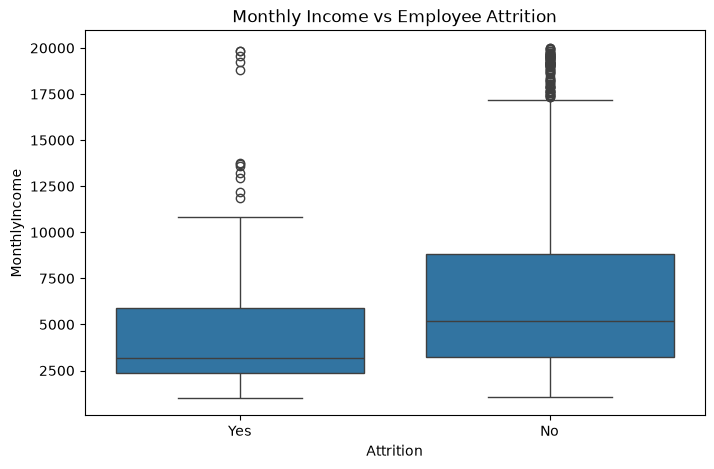

In [23]:
plt.figure(figsize=(8,5))

sns.boxplot(x="Attrition", y="MonthlyIncome", data=df)

plt.title("Monthly Income vs Employee Attrition")

plt.show()

Employees who left the organization generally have a lower monthly income compared to employees who stayed. This suggests that salary may influence employee retention.

### Work-Life Balance vs Attrition

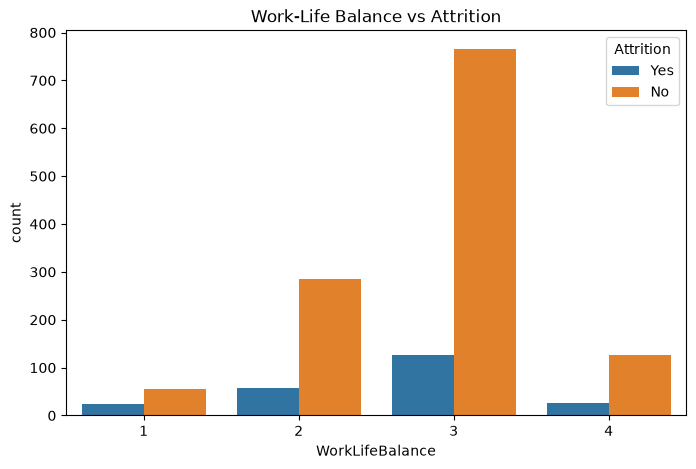

In [26]:
plt.figure(figsize=(8,5))

sns.countplot(x="WorkLifeBalance", hue="Attrition", data=df)

plt.title("Work-Life Balance vs Attrition")

plt.show()

Employees with poor work life balance tend to show higher attrition compared to employees with better work-life balance.

### Correlation Heatmap

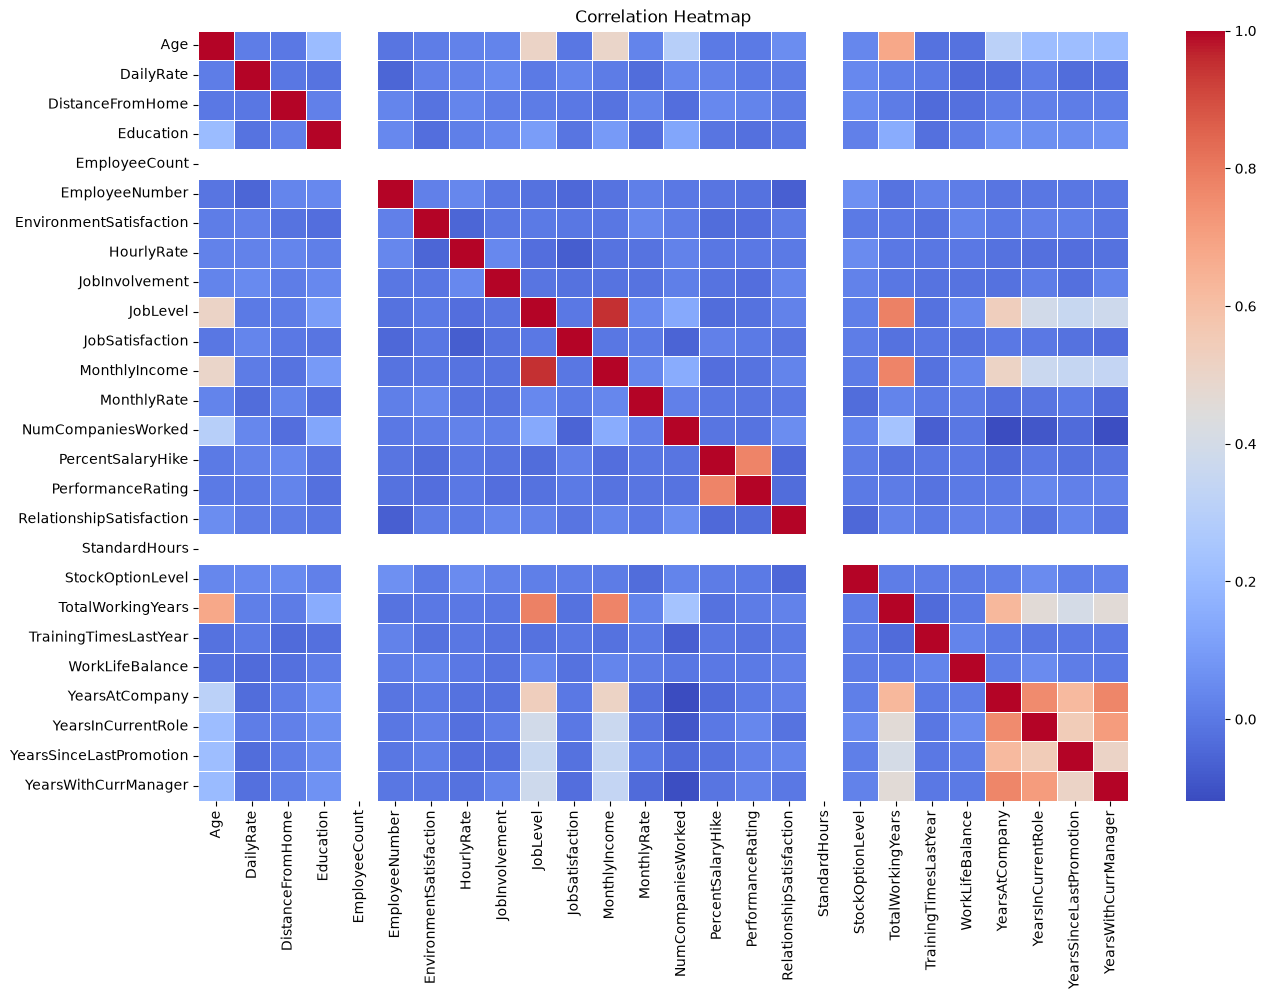

In [ ]:
plt.figure(figsize=(15,10))

sns.heatmap(df.corr(numeric_only=True),cmap="coolwarm",inewidths=0.5)

plt.title("Correlation Heatmap")

plt.show()

The heatmap shows correlations among numerical features. Most features exhibit weak to moderate correlations, indicating that they contribute different information to the model. No severe multicollinearity is observed among the major variables.

# Data Preprocessing

### Removing Unnecessary Features

The following columns were removed before model training as they do not provide useful information for prediction:

- **EmployeeCount** – Constant value for all employees.
- **EmployeeNumber** – Unique identifier.
- **StandardHours** – Constant value for all employees.

**Note:** These columns had already been removed earlier in the notebook. Re-running the same command results in a `KeyError` because they are no longer present in the DataFrame.

## Separating Features and Target Variable

The dataset is divided into:

- **Features (X):** All employee-related attributes used as input for prediction.
- **Target (y):** The Attrition column, which indicates whether an employee has left the organization.

In [34]:
X = df.drop("Attrition", axis=1)
y = df["Attrition"]

print("Shape of Features (X):", X.shape)
print("Shape of Target (y):", y.shape)

Shape of Features (X): (1470, 31)
Shape of Target (y): (1470,)


## Encoding Categorical Features

Machine learning algorithms cannot process categorical text values directly. Therefore, categorical features are converted into numerical form using **One-Hot Encoding**, which creates separate binary columns for each category without introducing any artificial order.

In [35]:
X = pd.get_dummies(X, drop_first=True)

print("Shape after encoding:", X.shape)

X.head()

Shape after encoding: (1470, 44)


,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,...,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,OverTime_Yes
0,41,1102,1,2,2,94,3,2,4,5993,...,False,False,False,False,False,True,False,False,True,True
1,49,279,8,1,3,61,2,2,2,5130,...,False,False,False,False,True,False,False,True,False,False
2,37,1373,2,2,4,92,2,1,3,2090,...,True,False,False,False,False,False,False,False,True,True
3,33,1392,3,4,4,56,3,1,3,2909,...,False,False,False,False,True,False,False,True,False,True
4,27,591,2,1,1,40,3,1,2,3468,...,True,False,False,False,False,False,False,True,False,False


## Train-Test Split

The dataset is divided into training and testing sets using an 80:20 ratio. The training set is used to train the machine learning models, while the testing set is used to evaluate their performance on unseen data.

In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

print("Training Features :", X_train.shape)
print("Testing Features  :", X_test.shape)
print("Training Target   :", y_train.shape)
print("Testing Target    :", y_test.shape)

Training Features : (1176, 44)
Testing Features  : (294, 44)
Training Target   : (1176,)
Testing Target    : (294,)


## Feature Scaling

Feature Scaling is applied using **StandardScaler** to standardize the numerical feature values. This ensures that features with larger numerical ranges do not dominate those with smaller ranges. Scaling is mainly required for distance-based and linear machine learning algorithms such as Logistic Regression.

In [37]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Scaling the training data
X_train_scaled = scaler.fit_transform(X_train)

# Scaling the testing data
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Successfull !")

Feature Scaling Successfull !


# Logistic Regression Model

Logistic Regression is used as the first baseline classification model. It estimates the probability of an employee leaving the organization based on the input features and classifies the employee into one of the two categories: **Attrition = Yes** or **Attrition = No**.

In [38]:
from sklearn.linear_model import LogisticRegression

# Creating the model
log_model = LogisticRegression(random_state=42)

# Training the model
log_model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully ")

Logistic Regression Model Trained Successfully 


# Model Evaluation - Logistic Regression

The trained Logistic Regression model is evaluated using various classification metrics, including Accuracy, Precision, Recall, F1-Score, Confusion Matrix, and ROC-AUC Score.

In [39]:
# Predicting on testing data

y_pred = log_model.predict(X_test_scaled)

In [40]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,roc_auc_score)

In [41]:
print("Accuracy :", accuracy_score(y_test, y_pred))

print("Precision :", precision_score(y_test, y_pred, pos_label="Yes"))

print("Recall :", recall_score(y_test, y_pred, pos_label="Yes"))

print("F1 Score :", f1_score(y_test, y_pred, pos_label="Yes"))

print("ROC-AUC :", roc_auc_score(y_test.map({"No":0,"Yes":1}),log_model.predict_proba(X_test_scaled)[:,1]))

Accuracy : 0.8605442176870748
Precision : 0.6153846153846154
Recall : 0.3404255319148936
F1 Score : 0.4383561643835616
ROC-AUC : 0.8079076578516668


In [42]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.88      0.96      0.92       247
         Yes       0.62      0.34      0.44        47

    accuracy                           0.86       294
   macro avg       0.75      0.65      0.68       294
weighted avg       0.84      0.86      0.84       294



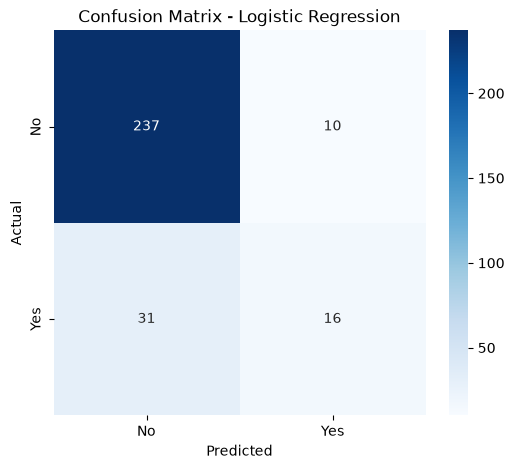

In [43]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=["No","Yes"],yticklabels=["No","Yes"])

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Confusion Matrix - Logistic Regression")

plt.show()

### Observation

The Logistic Regression model achieved an accuracy of **86.05%** on the test dataset. While the overall accuracy is good, the recall for the "Yes" class is relatively low, indicating that the model fails to identify a significant number of employees who actually leave the organization. This behavior is expected due to the class imbalance in the dataset. Therefore, more advanced models such as Random Forest and XGBoost will be evaluated to improve predictive performance.

# Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve prediction accuracy and reduce overfitting. It is widely used for classification tasks due to its robustness and ability to capture complex relationships in the data.

In [44]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100,random_state=42)

rf_model.fit(X_train, y_train)

print("Random Forest Model  Training Successfull ")

Random Forest Model  Training Successfull 


## Random Forest Model Evaluation

The performance of the Random Forest model is evaluated using Accuracy, Precision, Recall, F1-Score, ROC-AUC Score, Classification Report, and Confusion Matrix. These metrics help assess the model's effectiveness and compare it with Logistic Regression.

In [45]:
rf_pred = rf_model.predict(X_test)

In [46]:
print("Accuracy :", accuracy_score(y_test, rf_pred))

print("Precision :", precision_score(y_test, rf_pred, pos_label="Yes"))

print("Recall :", recall_score(y_test, rf_pred, pos_label="Yes"))

print("F1 Score :", f1_score(y_test, rf_pred, pos_label="Yes"))

print("ROC-AUC :", roc_auc_score(y_test.map({"No":0,"Yes":1}),rf_model.predict_proba(X_test)[:,1]))

Accuracy : 0.8333333333333334
Precision : 0.4166666666666667
Recall : 0.10638297872340426
F1 Score : 0.1694915254237288
ROC-AUC : 0.7861572917563958


In [47]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

          No       0.85      0.97      0.91       247
         Yes       0.42      0.11      0.17        47

    accuracy                           0.83       294
   macro avg       0.63      0.54      0.54       294
weighted avg       0.78      0.83      0.79       294



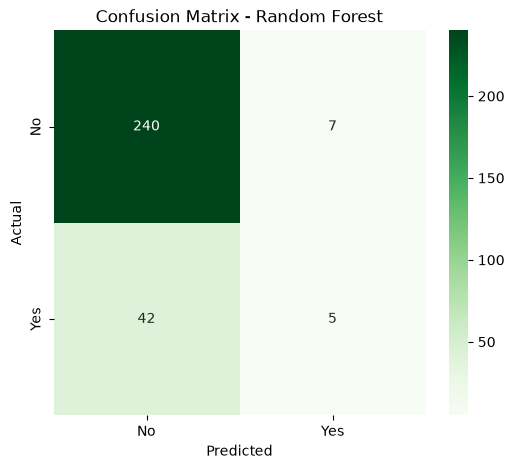

In [48]:
cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6,5))

sns.heatmap(cm,annot=True,fmt="d",cmap="Greens",xticklabels=["No","Yes"],yticklabels=["No","Yes"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest")

plt.show()

### Observation

The Random Forest model achieved an accuracy of **83.33%**. However, its recall and F1-score for predicting employee attrition were lower than those of Logistic Regression. This indicates that the model favored the majority class and struggled to correctly identify employees who left the organization. Therefore, further evaluation using XGBoost is performed to determine the best-performing model.

# XGBoost Classifier

XGBoost (Extreme Gradient Boosting) is an advanced ensemble learning algorithm that builds decision trees sequentially, where each new tree attempts to correct the errors made by previous trees. It is widely used for structured datasets because of its high predictive performance and robustness.

In [49]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

# Converting target labels into numeric values
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

xgb_model = XGBClassifier(random_state=42,eval_metric="logloss")

xgb_model.fit(X_train, y_train_encoded)

print("XGBoost Model Trained Successfully")

XGBoost Model Trained Successfully


## XGBoost Model Evaluation

The XGBoost model is evaluated using multiple classification metrics to measure its predictive performance. The results are compared with Logistic Regression and Random Forest to identify the best-performing model.

In [50]:
xgb_pred = xgb_model.predict(X_test)

In [51]:
print("Accuracy :", accuracy_score(y_test_encoded, xgb_pred))

print("Precision :", precision_score(y_test_encoded, xgb_pred))

print("Recall :", recall_score(y_test_encoded, xgb_pred))

print("F1 Score :", f1_score(y_test_encoded, xgb_pred))

print("ROC-AUC :", roc_auc_score(y_test_encoded,xgb_model.predict_proba(X_test)[:,1]))

Accuracy : 0.8605442176870748
Precision : 0.65
Recall : 0.2765957446808511
F1 Score : 0.3880597014925373
ROC-AUC : 0.7638039452149195


In [52]:
print(classification_report(y_test_encoded, xgb_pred))

              precision    recall  f1-score   support

           0       0.88      0.97      0.92       247
           1       0.65      0.28      0.39        47

    accuracy                           0.86       294
   macro avg       0.76      0.62      0.65       294
weighted avg       0.84      0.86      0.84       294



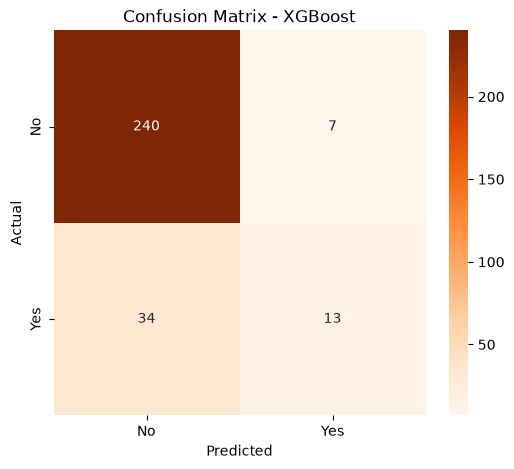

In [53]:
cm = confusion_matrix(y_test_encoded, xgb_pred)

plt.figure(figsize=(6,5))

sns.heatmap(cm,annot=True,fmt="d",cmap="Oranges",xticklabels=["No","Yes"],yticklabels=["No","Yes"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - XGBoost")

plt.show()

### Model Comparison Observation

Three machine learning models were evaluated for employee attrition prediction. Logistic Regression achieved the best overall balance between Accuracy, Recall, F1-Score, and ROC-AUC. Although XGBoost achieved the same accuracy, Logistic Regression demonstrated better Recall and F1-Score, making it the most suitable model for this dataset. Random Forest showed comparatively lower performance, particularly in identifying employees who were likely to leave.

# Model Comparison

Three machine learning models were trained and evaluated for employee attrition prediction. Their performances are compared using multiple evaluation metrics to identify the most suitable model for the given dataset.

In [ ]:
results = pd.DataFrame({"Model": ["Logistic Regression","Random Forest","XGBoost"],
    "Accuracy": [accuracy_score(y_test, y_pred),accuracy_score(y_test, rf_pred),accuracy_score(y_test_encoded, xgb_pred)],
    "Precision": [precision_score(y_test, y_pred, pos_label="Yes"),precision_score(y_test, rf_pred, pos_label="Yes"),precision_score(y_test_encoded, xgb_pred)],
    "Recall": [recall_score(y_test, y_pred, pos_label="Yes"),recall_score(y_test, rf_pred, pos_label="Yes"),recall_score(y_test_encoded, xgb_pred)],
    "F1 Score": [f1_score(y_test, y_pred, pos_label="Yes"),f1_score(y_test, rf_pred, pos_label="Yes"),f1_score(y_test_encoded, xgb_pred)],
    "ROC-AUC": [roc_auc_score(y_test.map({"No": 0, "Yes": 1}),log_model.predict_proba(X_test_scaled)[:, 1]),
        roc_auc_score(y_test.map({"No": 0, "Yes": 1}),rf_model.predict_proba(X_test)[:, 1]),roc_auc_score(y_test_encoded,xgb_model.predict_proba(X_test)[:, 1])]
})

results = results.round(4)

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8605,0.6154,0.3404,0.4384,0.8079
1,Random Forest,0.8333,0.4167,0.1064,0.1695,0.7862
2,XGBoost,0.8605,0.6500,0.2766,0.3881,0.7638


In [ ]:
results.style.highlight_max(subset=["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],color="green")

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.860500,0.615400,0.340400,0.438400,0.807900
1,Random Forest,0.833300,0.416700,0.106400,0.169500,0.786200
2,XGBoost,0.860500,0.650000,0.276600,0.388100,0.763800


### Observation

Among the three machine learning models, **Logistic Regression** achieved the best overall performance on the IBM HR Attrition dataset. Although XGBoost achieved a similar accuracy, Logistic Regression provided better Recall, F1-Score, and ROC-AUC, making it the most suitable model for predicting employee attrition in this project. Random Forest showed comparatively lower performance due to the class imbalance in the dataset.

# Feature Importance Analysis

Feature Importance is used to identify the most influential factors affecting employee attrition. It helps in understanding which employee attributes contribute the most to the prediction made by the machine learning model.

In [ ]:
# Extracting feature importance from Random Forest

feature_importance = pd.DataFrame({"Feature": X.columns,"Importance": rf_model.feature_importances_})

feature_importance = feature_importance.sort_values(by="Importance",ascending=False)

feature_importance.head(10)

,Feature,Importance
9,MonthlyIncome,0.072306
0,Age,0.072260
16,TotalWorkingYears,0.053589
1,DailyRate,0.051670
5,HourlyRate,0.047866
2,DistanceFromHome,0.047793
10,MonthlyRate,0.047228
19,YearsAtCompany,0.044137
43,OverTime_Yes,0.037830
22,YearsWithCurrManager,0.035452


C:\Users\ASUS\AppData\Local\Temp\ipykernel_27052\1963303000.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance.head(10),x="Importance",y="Feature",palette="viridis")


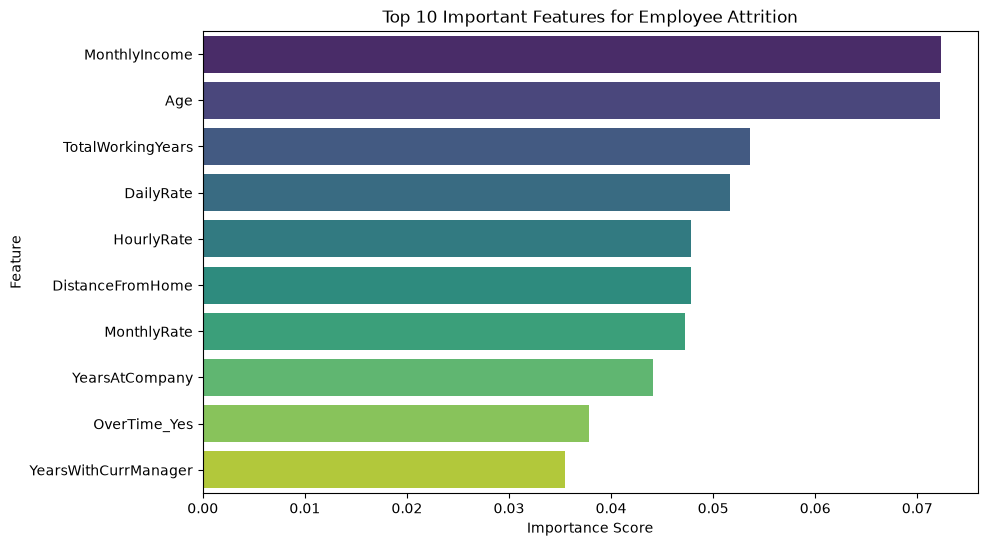

In [58]:
plt.figure(figsize=(10,6))

sns.barplot(data=feature_importance.head(10),x="Importance",y="Feature",palette="viridis")

plt.title("Top 10 Important Features for Employee Attrition")

plt.xlabel("Importance Score")

plt.ylabel("Feature")

plt.show()

### Observation

The feature importance analysis indicates that **Monthly Income**, **Age**, and **Total Working Years** are among the most influential features used by the model for predicting employee attrition. Other important factors include **Distance From Home**, **Years at Company**, **OverTime**, and **Years With Current Manager**. These results suggest that compensation, work experience, employee tenure, and work-related conditions play a significant role in predicting employee attrition.

# Saving the Trained Model

After evaluating all the machine learning models, **Logistic Regression** was selected as the final model because it achieved the best overall balance of Accuracy, Recall, F1-Score, and ROC-AUC on the test dataset.

The trained model and the preprocessing objects are saved using the **Joblib** library. Saving these objects allows the model to be reused for deployment without retraining and ensures consistent predictions in the Streamlit application.

In [60]:
import joblib

joblib.dump(log_model, "employee_attrition_model.pkl")

joblib.dump(scaler, "scaler.pkl")

print("Model and Scaler saved successfully!")

Model and Scaler saved successfully!


In [61]:
# Saving feature names used during training

joblib.dump(X.columns.tolist(), "feature_names.pkl")

print("Feature names saved successfully!")

Feature names saved successfully!


In [62]:
joblib.dump(label_encoder, "label_encoder.pkl")

print("Label Encoder saved successfully!")

Label Encoder saved successfully!
